# Codes that are not CSS: the three questions

> **In short.**
> * **The setting.** A *code* protects qubits by spreading them over more qubits. It is described by its *stabilizers*: products of Pauli operators ($X$ = bit flip, $Z$ = phase flip) that the protected state does not notice, so that measuring them reveals errors without disturbing the data. In the simplest codes (*CSS codes*) every stabilizer is all-$X$ or all-$Z$. Here the codes are not like that: their stabilizers mix $X$ and $Z$, like `XZZXI`.
> * **The question.** Does the tool still find the code, and what a block of gates does to the protected qubit, from the gates alone?
> * **The answer.** Yes. It finds the [[5,1,3]] code from a ring of CZ gates, builds its ideal encoder (checked with numpy) and writes it in the isometry AP normal form of Yeh et al., and finds that $H$ then $S$ on every qubit is the logical $SH$, while $H$ alone leaves the code. One case is not covered: a code that differs from run to run.
> * **How to read the pictures.** Lines are qubits, time runs left to right; green and red dots are Z- and X-spiders, and a blue line between two green dots is a CZ gate. Shades mark the blocks of a program.
> * New to codes and ZX-diagrams? Start with [TInjectionWalkthrough.ipynb](TInjectionWalkthrough.ipynb), Part A.

In a *CSS code* every stabilizer is made of `X`s only or of `Z`s only (the Steane code, the surface code). Many codes are not like that. The best known is the **[[5,1,3]] code**, the smallest code that corrects any error on one qubit: its stabilizers mix `X` and `Z`, for example `XZZXI`.

This notebook shows that the tool answers all three questions of the paper for such codes, from the gates alone:

1. **which code** the qubits are in: the stabilizers are read off the program, mixed ones included;
2. **what a block does** to the logical qubits: computed between *ideal encoders*. For a code that is not CSS, the tool builds the ideal encoder from its Choi state, following Yeh, Huang, Kissinger, Li and van de Wetering (*A three-way normal form for stabiliser codes*, in preparation);
3. whether it does so **in every run**.

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, '..')                      # for the test suite's Steane encoder
import numpy as np
import pyzx as zx
from pyzx.circuit import Circuit
from pyzx.circuit.gates import CNOT, CZ, HAD, S, Measurement, Reset
from zxqec.qprogram import QProgram, ParityControlled, check_detectors
from zxqec.codes import code_of, iap_normal_form, logical_action, reduced_ap_form
from zxqec.spacetime import draw_graph, draw_program, draw_relaxed
from tests.programs import steane_encoder

CHECKS = ['XZZXI', 'IXZZX', 'XIXZZ', 'ZXIXZ']       # four of the code's checks

def five_qubit_program(gate=None, name=None):
    """Qubit 0 carries the input, qubits 1-5 hold the [[5,1,3]] code, qubit 6 measures the checks."""
    p = QProgram(7, bits=5, initial_states={**{q: '+' for q in range(1, 6)}, 6: '0'})
    c = Circuit(7, bit_amount=5)
    c.add_gate(HAD(0))
    for q in range(1, 6):
        c.add_gate(CZ(q, q % 5 + 1))                # a ring of CZ gates on qubits 1-5
    for q in range(1, 6):
        c.add_gate(CZ(0, q))                        # join the input to every qubit of the ring
    c.add_gate(HAD(0))
    c.add_gate(Measurement(0, result_symbol='c[0]'))    # and measure it in the X basis
    p.add_circuit(c, name='encode')
    c = Circuit(7, bit_amount=5)
    for k, check in enumerate(CHECKS):              # measure each check with the helper qubit
        c.add_gate(HAD(6))
        for j, letter in enumerate(check):
            if letter == 'X':
                c.add_gate(CNOT(6, 1 + j))
            if letter == 'Z':
                c.add_gate(CZ(6, 1 + j))
        c.add_gate(HAD(6))
        c.add_gate(Measurement(6, result_symbol='c[%d]' % (k + 1)))
        c.add_gate(Reset(6))
    p.add_circuit(c, name='measure the four checks')
    if gate is not None:                            # a gate on every qubit of the code
        c = Circuit(7, bit_amount=5)
        for q in range(1, 6):
            for g in gate:
                c.add_gate(g(q))
        p.add_circuit(c, name=name)
    return p

## 1. Which code?

The encoder is a ring of `CZ` gates with the input joined to every qubit and then measured. Nothing in the program says "[[5,1,3]]".

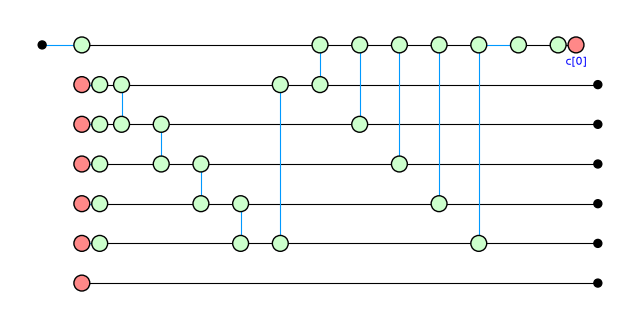

In [2]:
p = five_qubit_program()
draw_graph(p.stage_graph(0, classical=False), show_time=False, figsize=(8, 4))

The encoder stage as a ZX-diagram, time running left to right: qubit 0 (top) carries the input (its wire starts with a Hadamard, the blue segment), qubits 1-5 start in $|+\rangle$; the blue lines between them are the ring of CZ gates, then the CZ gates from qubit 0 to each of them, and qubit 0 is measured at the end (`c[0]`). Qubit 6, the helper for the checks, is idle here.

And the code the tool reads off the program after this stage:

In [3]:
print(p.code_at(0))

[[5, 1, 3]] stabilizer code on qubits 1, 2, 3, 4, 5
    stabilizer +XZZXI
    stabilizer +ZZXIX
    stabilizer +ZXIXZ
    stabilizer +IXZZX
    logical X XXXXX   logical Z ZZZZZ
fixed qubits: 6 in |0>


The tool finds a **[[5,1,3]] stabilizer code** (not "CSS code") on qubits 1-5. Its generators mix `X` and `Z`: they are four of the five cyclic shifts of `XZZXI`, which generate the code's stabilizer group. The logical operators are `XXXXX` and `ZZZZZ`. The helper qubit 6 is left in `|0>`.

## 2. The ideal encoder

The logical action of a block is computed between *ideal encoders*: the map `E` from the logical qubit to the code with `E X = Xbar E`, `E Z = Zbar E`, whose image is the code space. For CSS codes the tool draws `E` as a two-layer diagram; that form cannot give a code that is not CSS, so here `code.encoder()` builds `E` from its Choi state instead. We check the three properties with numpy:

In [4]:
code = p.code_at(0).data()                         # the code on qubits 1-5, without the helper qubit
E = code.encoder().to_matrix()
E = E / np.linalg.norm(E[:, 0])                     # the diagram is built up to a scalar

PAULI = {'I': np.eye(2), 'X': np.array([[0, 1], [1, 0]]), 'Y': np.array([[0, -1j], [1j, 0]]),
         'Z': np.diag([1, -1])}
def matrix(p):
    m = np.array([[1]])
    for letter in p.letters:
        m = np.kron(m, PAULI[letter])
    return (-1) ** int(p.sign) * m

print("every stabilizer fixes E:    ", max(np.abs(matrix(g) @ E - E).max() for g in code.stabilizers))
print("Xbar E = E X:                ", np.abs(matrix(code.logical_x[0]) @ E - E @ PAULI['X']).max())
print("Zbar E = E Z:                ", np.abs(matrix(code.logical_z[0]) @ E - E @ PAULI['Z']).max())
print("E is an isometry (E^dag E = I):", np.abs(E.conj().T @ E - np.eye(2)).max())

every stabilizer fixes E:     6.123233995736765e-17
Xbar E = E X:                 9.184850993605147e-17
Zbar E = E Z:                 0.0
E is an isometry (E^dag E = I): 0.0


All four are zero up to rounding: `E` is the ideal encoder of the [[5,1,3]] code.

The ideal encoder itself is a ZX-diagram. As the library builds it from the Choi state, it has the three layers of Yeh et al.'s normal form (Z-spiders, X-spiders, then CZ gates on the outputs), and many of its spiders are plain wires (phase 0, two legs), which hide its shape. PyZX's two simplest rules, removing those spiders (`id_simp`) and fusing neighbours of the same colour (`spider_simp`), give the same map in a few spiders. Both drawn with `draw_relaxed` (the positions only show what is connected to what), as built and simplified:

the same map: True


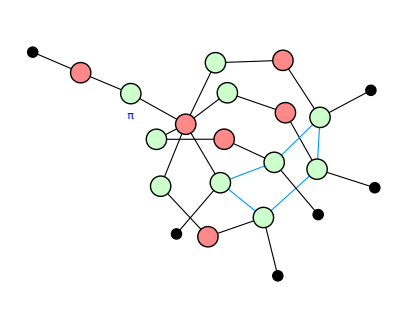

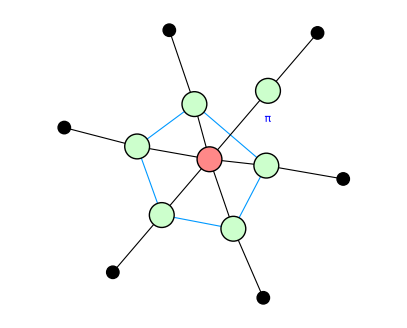

In [5]:
simple = code.encoder().clone()
zx.simplify.id_simp(simple)
zx.simplify.spider_simp(simple)
print("the same map:", zx.compare_tensors(code.encoder(), simple, preserve_scalar=False))
display(draw_relaxed(code.encoder(), figsize=(5, 4)))
draw_relaxed(simple, figsize=(5, 4))

Simplified, it is the textbook picture of the [[5,1,3]] code. The five qubits (green, each with its output wire) are joined in a ring of CZ gates (the blue Hadamard edges): the ring of the program's encoder. The input reaches all five through one red spider, which copies it in the X basis, $|+\rangle \mapsto |+\rangle^{\otimes 5}$ and $|-\rangle \mapsto |-\rangle^{\otimes 5}$, before the ring. So the code words are the ring states $\mathrm{CZ}_{\text{ring}}|+\rangle^{\otimes 5}$ and $\mathrm{CZ}_{\text{ring}}|-\rangle^{\otimes 5}$: the [[5,1,3]] code as a graph code on a ring of five.

The $\pi$ on the input (a $Z$ gate) fixes the signs. With it, $E X = \bar X E$ for $\bar X = +XXXXX$, as checked above; without it, $\bar X E = -E X$:

In [6]:
pi_spider = next(v for v in simple.vertices() if simple.phase(v) == 1)
no_pi = simple.clone()                              # clone keeps the vertex numbers
no_pi.set_phase(pi_spider, 0)
E0 = no_pi.to_matrix()
E0 = E0 / np.linalg.norm(E0[:, 0])
print("without the pi:  Xbar E = E X:", np.allclose(matrix(code.logical_x[0]) @ E0, E0 @ PAULI['X']),
      "   Xbar E = -E X:", np.allclose(matrix(code.logical_x[0]) @ E0, -E0 @ PAULI['X']))

without the pi:  Xbar E = E X: False    Xbar E = -E X: True


### The isometry AP normal form

Yeh, Huang, Kissinger, Li and van de Wetering write every Clifford isometry, such as an ideal encoder, in a normal form of three layers (the *isometry affine-with-phases normal form*, Theorem 4.2 of their draft), read from the inputs to the outputs:

* $U_I$, a Clifford on the logical inputs: phases (multiples of $\pi/2$) and CZ gates, then Hadamards, then X-CZ gates (two red spiders joined by a Hadamard edge);
* the **core**, a phase-free CSS encoder in X-Z parity form: a red spider on each input and one for each Z-check, each with a phase $0$ or $\pi$, joined to a green spider on each output;
* $U_O$, a diagonal Clifford on the outputs: phases in multiples of $\pi/2$ and CZ gates.

`iap_normal_form` computes it with their algorithm (shown step by step below), from a code or from the diagram of any Clifford isometry, and `draw` shades the three layers. For the [[5,1,3]] code:

isometry AP normal form: 1 input(s) -> 5 output(s)
  U_I   phases none; CZ none; H on inputs none; X-CZ none
  core  input X-spiders: input 0 -> outputs {1, 2, 3, 4, 5}
        Z-check X-spiders: none
  U_O   phases 1: pi, 2: pi, 3: pi, 4: pi, 5: pi; CZ 1-2, 1-5, 2-3, 3-4, 4-5
the same map as the ideal encoder: True


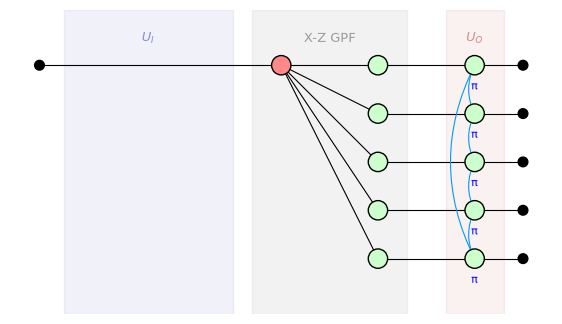

In [7]:
nf = iap_normal_form(code)
print(nf)
print("the same map as the ideal encoder:", zx.compare_tensors(nf.to_graph(), code.encoder(), preserve_scalar=False))
nf.draw()

Read from left to right. $U_I$ is empty: the logical qubit needs no Clifford before the core. The core copies the input in the X basis onto all five qubits (its one red spider is joined to all five green ones) and has no Z-checks. $U_O$ is the ring of CZ gates, with a $\pi$ on every qubit, which gives the logical $X$ its sign. It is the simplified picture above, now in the three layers of the normal form.

### How the normal form is computed: Yeh et al.'s algorithm, step by step

`iap_normal_form` follows Algorithm 3 of Yeh et al. It starts from the encoder's **Choi state**: bend the input wires round, and an encoder from $k$ qubits to $n$ becomes a state of $k + n$ qubits, the inputs first. Every such state can be written in exactly one way in **reduced AP form** ("affine with phases"; `reduced_ap_form`):

* a green spider on each of the $k + n$ qubits;
* a red spider for each parity the state fixes, joined to the qubits of that parity. These are the rows of a matrix $B$ in reduced row echelon form: each row has a first qubit, its *pivot*, that no other row has;
* phases (multiples of $\pi/2$) and CZ gates (blue), but only on the *free* qubits, the ones that are no row's pivot.

The algorithm then builds the three layers.

1. **Cut off** the phases and CZ gates among the inputs: they are the first layer of $U_I$. Those among the outputs are $U_O$. What remains is the red spiders and the CZ gates between an input and an output.
2. **Go through the inputs from the top.**
   * **Case 1**: the input is the pivot of a row. That red spider is the input's spider in the core; nothing to do.
   * **Case 2**: the input is in no row, so it has only CZ gates to outputs. Changing its colour turns it into a red spider joined to those outputs, with a Hadamard before it: a Hadamard in $U_I$.
   * **Case 3**: the input is in the row of an earlier input (that row's pivot). It gets a Hadamard and a red spider as in Case 2, and it leaves that row, which costs an X-CZ gate between the two inputs in $U_I$.
3. **What is left is the core.** The rows with an input pivot are its logical spiders; the rows with an output pivot are its Z-checks.

For the [[5,1,3]] code, the input is the pivot of the only row (Case 1). All the phases and CZ gates are on the outputs, and become $U_O$; $U_I$ is empty:

In [8]:
print(reduced_ap_form(code))

reduced AP form on 6 variables: in0, 1, 2, 3, 4, 5
  rows of B (X-spiders): {in0, 1, 2, 3, 4, 5}, pivot in0
  free variables: 1, 2, 3, 4, 5
  phases: 1: pi, 2: pi, 3: pi, 4: pi, 5: pi
  CZ: 1-2, 1-5, 2-3, 3-4, 4-5


The inputs are named `in0, in1, ...`; the outputs keep their qubit names. A small made-up encoder shows all three cases: logical qubits 0, 1 and 2, one more qubit, 3, that starts in $|0\rangle$, and six gates. `prefix_graph(0)` is the encoder as a ZX-diagram, with 3 inputs and 4 outputs; its reduced AP form, drawn with the inputs on the left, is the same map:

reduced AP form on 7 variables: in0, in1, in2, 0, 1, 2, 3
  rows of B (X-spiders): {in0, in1, 0, 1}, pivot in0; {2, 3}, pivot 2
  free variables: in1, in2, 0, 1, 3
  phases: none
  CZ: in1-3, in2-0, 1-3
the same map as the encoder: True


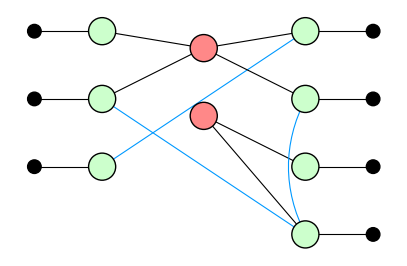

In [9]:
small = QProgram(4, initial_states={3: '0'})
c = Circuit(4)
for gate in [HAD(2), CNOT(0, 2), CNOT(2, 0), CNOT(2, 1), HAD(2), CNOT(2, 3)]:
    c.add_gate(gate)
small.add_circuit(c, name='encode')
E_small = small.prefix_graph(0)
ap = reduced_ap_form(E_small)
print(ap)
print("the same map as the encoder:", zx.compare_tensors(ap.to_graph(inputs=3), E_small, preserve_scalar=False))
draw_graph(ap.to_graph(inputs=3), time_axis=False, show_time=False, figsize=(5, 3.2))

Read the picture from left to right: the three inputs (green), the two rows (red), the four outputs (green).

1. **Cut off.** There are no phases, and no CZ gate between two inputs, so the first layer of $U_I$ is empty. The CZ gate between outputs 1 and 3 is $U_O$.
2. **The inputs, from the top.**
   * `in0` is the pivot of the first row, $\{$`in0, in1`, 0, 1$\}$: **Case 1**. Its red spider, without `in1`, is the core's spider for input 0, joined to outputs 0 and 1.
   * `in1` is not a pivot, and it is in the row of `in0`: **Case 3**. It gets a Hadamard and a red spider joined to output 3 (its CZ gate), and leaves the row of `in0` with an X-CZ gate between inputs 0 and 1.
   * `in2` is in no row: **Case 2**. A Hadamard, and a red spider joined to output 0 (its CZ gate).
3. **The core.** The three logical spiders, and the second row, $\{2, 3\}$, whose pivot is an output: a Z-check, $Z_2 Z_3$.

The code itself is simple: $Z_2 Z_3$ is its only check, and qubits 0 and 1 carry logical qubits as they are. The six gates also mix the three logical qubits, and that mixing is what $U_I$ records. The normal form, and the check that it is the same map:

isometry AP normal form: 3 input(s) -> 4 output(s)
  U_I   phases none; CZ none; H on inputs [1, 2]; X-CZ 0-1
  core  input X-spiders: input 0 -> outputs {0, 1}, input 1 -> outputs {3}, input 2 -> outputs {0}
        Z-check X-spiders: outputs {2, 3}
  U_O   phases none; CZ 1-3
the same map as the encoder: True


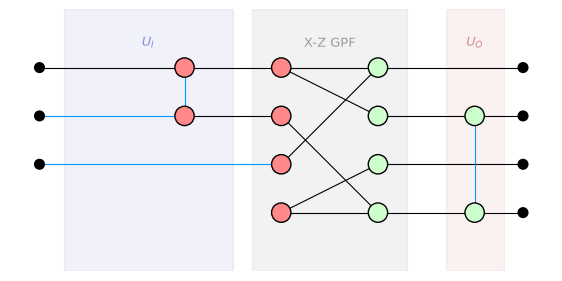

In [10]:
nf_small = iap_normal_form(E_small)
print(nf_small)
print("the same map as the encoder:", zx.compare_tensors(nf_small.to_graph(), E_small, preserve_scalar=False))
nf_small.draw()

## 3. Blocks and what they do

Now a whole program: encode, measure the four checks, and apply `H` then `S` to every qubit of the code. The last block is given the role *transversal gate* (see `TransversalGates.ipynb`).

In [11]:
p = five_qubit_program([HAD, S], 'H then S on every qubit')
level = p.group_stages([(0, 0, 'encode', 'encoder'), (1, 1, 'checks', 'syndrome extraction'),
                        (2, 2, 'H then S on every qubit', 'transversal gate')])
s = p.summary(level)
print(s.table())
print()
print(s.blocks[2].describe())
print()
print("the same code after the gate as before:", s.blocks[2].code_in.same_code_as(s.blocks[2].code_out))

block                      role                 code before  code after  logical action  every run?  checks
0 encode                   encoder              [[1,1,1]]    [[5,1,3]]   I               yes         ok
1 checks                   syndrome extraction  [[5,1,3]]    [[5,1,3]]   I               yes         ok
2 H then S on every qubit  transversal gate     [[5,1,3]]    [[5,1,3]]   SH              yes         ok

Block 2 'H then S on every qubit' (transversal gate) -- stages 2
  code before: [[5,1,3]] on qubits 1,2,3,4,5
  code after:  [[5,1,3]] on qubits 1,2,3,4,5
  logical action: deterministic: every run implements SH
  ok      implements SH in every run
  ok      transversal: no two qubits of one code block are connected by its gates

the same code after the gate as before: True


The program, one shade per block: the encoder, the four checks (each measured with helper qubit 6, which is reset after each measurement), and $H$ then $S$ on every qubit of the code.

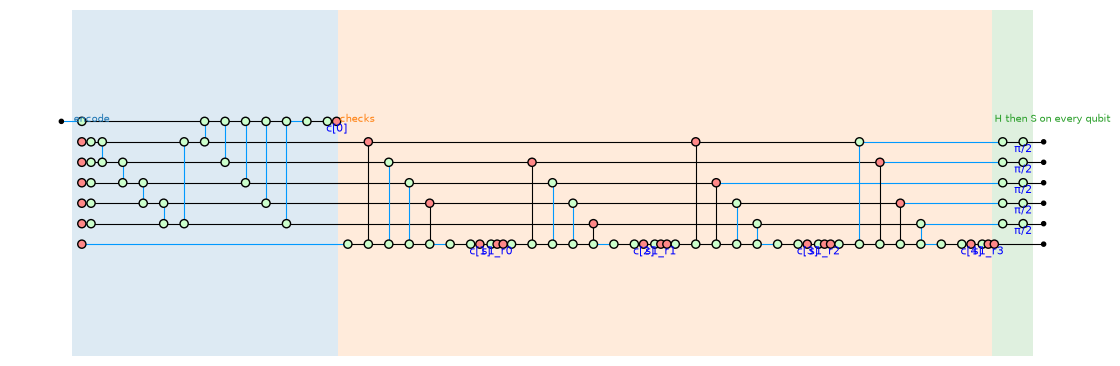

In [12]:
draw_program(p, level=level, show_time=False, figsize=(14, 4.5))

* The **encoder** puts the input into the code without changing it (`I`).
* The **round of checks** leaves the code and the logical state alone.
* `H` then `S` on every qubit **keeps the [[5,1,3]] code** and is the **logical `SH`**, in every run (`SH` is the operator: first `H`, then `S`). It is a Clifford gate of order three, which the [[5,1,3]] code is known to have transversally; here it is found from the gates.

The four check results are always 0, since the code was just prepared. `check_detectors` confirms it:

In [13]:
print(check_detectors(p, [['c[1]'], ['c[2]'], ['c[3]'], ['c[4]']]))

4 declared detector(s): 4 deterministic (value 0), 0 not deterministic, 0 unknown
the program has 4 independent detectors on its results, all sums of declared ones


### A gate on every qubit that does not keep the code

`H` on every qubit is transversal too, but it maps the [[5,1,3]] code to a *different* code (its stabilizers become `ZXXZI` and its shifts). Asked for the logical action from the [[5,1,3]] code back to the [[5,1,3]] code, the tool says the block leaves it:

In [14]:
q = five_qubit_program([HAD], 'H on every qubit')
level = q.group_stages([(0, 0, 'encode', 'encoder'), (1, 1, 'checks', 'syndrome extraction'),
                        (2, 2, 'H on every qubit', 'transversal gate')])
b = q.summary(level).blocks[2]
print("the same code after the gate as before:", b.code_in.same_code_as(b.code_out))
act = logical_action(q.block_graph(level, 2, classical=False), b.code_in, b.code_in)
print(act.verdict())

the same code after the gate as before: False
leaves the code: the block maps part of the code before it outside the code after it, so it is not a logical operation (between the ideal encoders it looks like H, but shrunk)


## 4. The Steane code after one S gate

An `S` gate on one qubit of the Steane code gives a code that is not CSS (on that qubit, `X` becomes `Y` in the stabilizers). `S^dag` on that qubit, then `H` on every qubit, then `S` on that qubit again, is a logical `H` of the new code:

In [15]:
p = QProgram(7, initial_states={q: '0' for q in range(7) if q != 3})
c = Circuit(7)
for gate in steane_encoder(list(range(7))):
    c.add_gate(gate)
p.add_circuit(c, name='encode')
c = Circuit(7)
c.add_gate(S(0))
p.add_circuit(c, name='S on qubit 0')
c = Circuit(7)
for _ in range(3):
    c.add_gate(S(0))                                # S^dag = S^3
for q in range(7):
    c.add_gate(HAD(q))
c.add_gate(S(0))
p.add_circuit(c, name='H in the new code')
print(p.code_at(1))
print()
print(p.summary(p.group_stages([(0, 0, 'encode', 'encoder'), (1, 1, 'S on qubit 0', 'logical gate'),
                                (2, 2, 'H in the new code', 'transversal gate')])).table())

[[7, 1, 3]] stabilizer code on qubits 0, 1, 2, 3, 4, 5, 6
    stabilizer +IXXXIXI
    stabilizer +IXIXXIX
    stabilizer +YXXIXII
    stabilizer +ZZZIZII
    stabilizer +ZZIIIZZ
    stabilizer +ZIZZIIZ
    logical X IXXIIIX   logical Z ZZIZIII



block                role              code before  code after  logical action  every run?  checks
0 encode             encoder           [[1,1,1]]    [[7,1,3]]   I               yes         ok
1 S on qubit 0       logical gate      [[7,1,3]]    [[7,1,3]]   I               yes         ok
2 H in the new code  transversal gate  [[7,1,3]]    [[7,1,3]]   H               yes         ok


The `S` gate is the logical identity from the Steane code into the new code, and the conjugated Hadamards are its logical `H`, in every run.

Both codes in the isometry AP normal form. They share the core, the Steane code itself (the input joined to qubits 3, 5, 6, and its three Z-checks), and the $S$ shows up only in $U_O$. But not on qubit 0: $U_O$ acts only on the qubits the Z-checks leave free (3, 4, 5, 6; qubits 0, 1, 2 are the pivots of the checks), and on the code the value of qubit 0 is $z_3 \oplus z_4 \oplus z_5$ (the first Z-check). So $S$ on qubit 0, the phase $i^{z_0}$, is $i^{z_3 + z_4 + z_5} (-1)^{z_3 z_4 + z_3 z_5 + z_4 z_5}$: $S$ on qubits 3, 4, 5 and a CZ between each pair. Writing every phase on the free qubits is what makes the form unique.

the Steane code
isometry AP normal form: 1 input(s) -> 7 output(s)
  U_I   phases none; CZ none; H on inputs none; X-CZ none
  core  input X-spiders: input 0 -> outputs {3, 5, 6}
        Z-check X-spiders: outputs {0, 3, 4, 5}, outputs {1, 3, 4, 6}, outputs {2, 4, 5, 6}
  U_O   phases none; CZ none
  the same map as the ideal encoder: True

after S on qubit 0
isometry AP normal form: 1 input(s) -> 7 output(s)
  U_I   phases none; CZ none; H on inputs none; X-CZ none
  core  input X-spiders: input 0 -> outputs {3, 5, 6}
        Z-check X-spiders: outputs {0, 3, 4, 5}, outputs {1, 3, 4, 6}, outputs {2, 4, 5, 6}
  U_O   phases 3: pi/2, 4: pi/2, 5: pi/2; CZ 3-4, 3-5, 4-5
  the same map as the ideal encoder: True



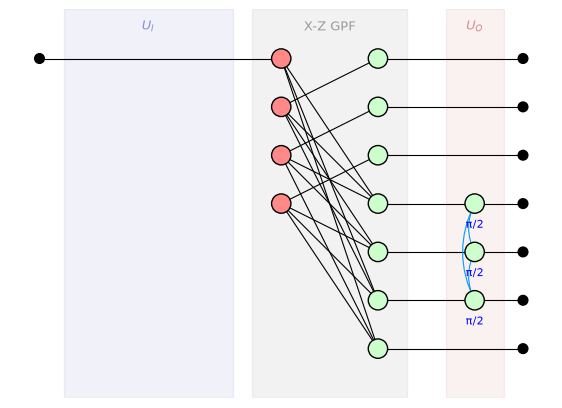

In [16]:
for name, c in (("the Steane code", p.code_at(0)), ("after S on qubit 0", p.code_at(1))):
    print(name)
    print(iap_normal_form(c))
    print("  the same map as the ideal encoder:",
          zx.compare_tensors(iap_normal_form(c).to_graph(), c.encoder(), preserve_scalar=False))
    print()
iap_normal_form(p.code_at(1)).draw()

### Why the normal form is there: a block is checked on the CSS core

This is what the normal form is for in the framework (thesis, Section 4.5). The check of a block such as a transversal gate works on a CSS encoder in parity form, with the non-Clifford phases as Z-phase gadgets. For a code that is not CSS, `logical_action` therefore puts the block $B$ between the normal forms of the codes before and after it,

$$U_I^\dagger\, C^\dagger\, U_O^\dagger \;\cdot\; B \;\cdot\; U_O\, C\, U_I .$$

When the block is diagonal and both codes have the same $U_O$, the two $U_O$ cancel, since diagonal gates commute: the block is checked on the CSS core $C$, exactly as for a CSS code, and $U_I$ only relabels the logical qubits (`on_core()` gives the action on the cores alone). $S$ on every qubit of the new code is diagonal. On its core, the Steane code, it is the logical $S^\dagger$, as transversal $S$ is in the Steane code itself:

In [17]:
r = QProgram(7, initial_states={q: '0' for q in range(7) if q != 3})
for name, gates in (("encode", steane_encoder(list(range(7)))), ("S on qubit 0", [S(0)]),
                    ("S on every qubit", [S(q) for q in range(7)])):
    c = Circuit(7)
    for gate in gates:
        c.add_gate(gate)
    r.add_circuit(c, name=name)
act = r.logical_action(0, 2)
print(act.describe())
print("on the CSS core alone:", act.on_core().verdict())

logical action: 1 -> 1 logical qubit(s)
  through the isometry AP normal forms: U_O cancelled (the block is diagonal), so the block is checked on the CSS core; U_I before: empty; U_I after: empty
  in every run: S^dag
  deterministic: every run implements S^dag
on the CSS core alone: deterministic: every run implements S^dag


The logical $H$ above is not diagonal. Its two $U_O$ are kept, and the composite is reduced as a whole; the answer is the same as before, $H$:

In [18]:
print(p.logical_action(0, 2).describe())

logical action: 1 -> 1 logical qubit(s)
  through the isometry AP normal forms: U_O kept; U_I before: empty; U_I after: empty
  in every run: H
  deterministic: every run implements H


### The thesis's case, step by step: transversal $T$ on a code that is not CSS

**The question.** We have an encoder $E$ of a code that is not CSS, and a block $B$: $T$ on every qubit. Does $B$ act on the encoded qubit as a logical gate, and which one? The tool answers by computing the *logical action*

$$L = E^\dagger \cdot B \cdot E \qquad \text{(encode, apply } B\text{, decode)}$$

and simplifying it until it can be read. The isometry AP normal form is used once, in step 4: it turns the question into the same question on a CSS code, the case the thesis's check (spider-nest identities, triorthogonality) handles. Then:

| step | what happens |
|---|---|
| 1 | the encoder $E$, as a circuit and a ZX-diagram |
| 2 | the code it encodes, read off the diagram |
| 3 | $E$ in isometry AP normal form, $E = U_O \cdot C \cdot U_I$ |
| 4 | $L = E^\dagger B E$: the two $U_O$ cancel, so $L = C^\dagger B\, C$, a question about the CSS core $C$ |
| 5 | that composite, $C^\dagger B\, C$, as a ZX-diagram |
| 6 | simplified: the 15 $T$ gates become 15 phase gadgets |
| 7 | the gadgets added up: 14 of 15 parts cancel (triorthogonality), one $T^\dagger$ is left |
| 8 | the answer read off, and the checks |

**Step 1. The encoder.** PyZX builds the encoder of any CSS code from its X-checks and logical X operators (`pyzx.css.generate_css_encoder_graph`, as in PyZX's demo `CSSLogicalOperators.ipynb`). We take the [[15,1,3]] Reed-Muller code, on which transversal $T$ is known to be the logical $T^\dagger$, and put a layer of $S$ and CZ gates after its encoder. Reading the picture from the left: the input, its green spider and four more green spiders (the four X-checks), the 15 red spiders on the outputs (which green spider reaches which output is the code), then the layer: $S$ gates ($\pi/2$) and CZ gates (blue edges).

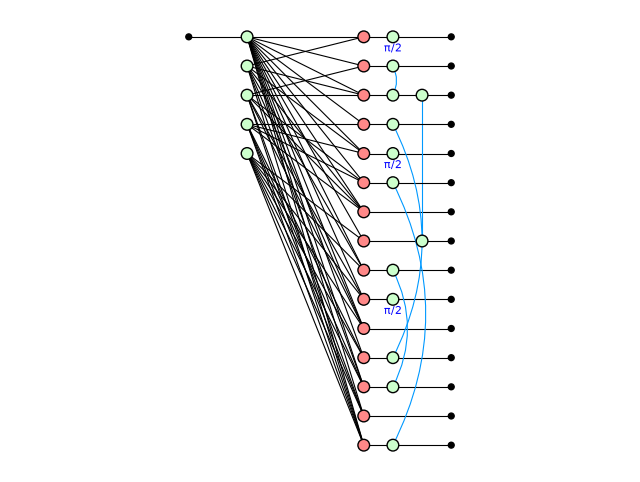

In [19]:
from pyzx.css import generate_css_encoder_graph
from pyzx.linalg import Mat2
from pyzx.circuit.gates import T

SX = Mat2([[1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1],      # the four X-checks of [[15,1,3]]
           [0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1],
           [0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1],
           [0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1]])
LX = Mat2([[1] * 15])                                            # the logical X
rm15, _ = generate_css_encoder_graph(SX, LX, 'Z-X')
rm15.auto_detect_io()
layer = Circuit(15)
for gate in [S(0), S(4), S(9), CZ(1, 2), CZ(2, 7), CZ(3, 11), CZ(5, 14), CZ(8, 12)]:
    layer.add_gate(gate)
E = rm15 + layer.to_graph()                                      # the encoder, then the layer
zx.draw_matplotlib(E, figsize=(8, 6))

**Step 2. The code.** `code_of` reads the code off the diagram: still 15 qubits, one logical qubit, distance 3, but the layer has mixed $X$ and $Z$ into the stabilizers (the $Y$ letters), so the code is not CSS.

In [20]:
code15 = code_of(E)
print(code15.parameters, "CSS:", code15.is_css)
print(code15)

(15, 1, 3) CSS: False
[[15, 1, 3]] stabilizer code on qubits 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14
    stabilizer +XXIYIIXXIIXIXXI
    stabilizer +XXIIXYIIXXIIXXI
    stabilizer -YIXXIXIIXIXXIXI
    stabilizer +XXIXIIXIXXZXIIX
    stabilizer +ZZIZIIZIIIIIIII
    stabilizer +ZZIIZZIIIIIIIII
    stabilizer +ZZIIIIIZIIZIIII
    stabilizer +ZZIIIIIIZZIIIII
    stabilizer +ZZIIIIIIIIIZIIZ
    stabilizer +ZZIIIIIIIIIIZZI
    stabilizer +ZIZZIZIIIIIIIII
    stabilizer +ZIZIIIIZIZIIIII
    stabilizer +ZIZIIIIIIIIZIZI
    stabilizer +ZIIZIIIZIIIIZII
    logical X IXIIXIXXIXIIXIX   logical Z ZZZIIIIIIIIIIII


**Step 3. The isometry AP normal form.** $E = U_O \cdot C \cdot U_I$. Here $U_I$ is empty, the core $C$ is the [[15,1,3]] code again (the input reaches qubits 6, 10, 12, 13, 14; ten Z-checks), and $U_O$ is the layer, the same diagonal on the code, written on the qubits the Z-checks leave free (6, 10, 12, 13, 14): a $\pi$ on 6 and 14, $\pi/2$ on 13 and five CZ gates.

isometry AP normal form: 1 input(s) -> 15 output(s)
  U_I   phases none; CZ none; H on inputs none; X-CZ none
  core  input X-spiders: input 0 -> outputs {6, 10, 12, 13, 14}
        Z-check X-spiders: outputs {0, 6, 10, 12}, outputs {1, 6, 10, 13}, outputs {2, 6, 10, 14}, outputs {3, 6, 12, 13}, outputs {4, 6, 12, 14}, outputs {5, 6, 13, 14}, outputs {7, 10, 12, 13}, outputs {8, 10, 12, 14}, outputs {9, 10, 13, 14}, outputs {11, 12, 13, 14}
  U_O   phases 6: pi, 13: pi/2, 14: pi; CZ 6-13, 10-12, 10-13, 10-14, 13-14


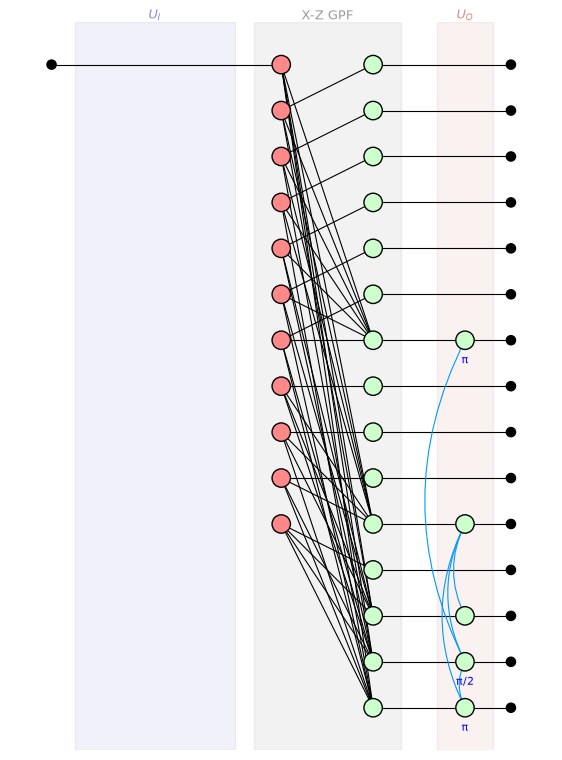

In [21]:
nf15 = iap_normal_form(code15)
print(nf15)
nf15.draw()

**Step 4. The question, and where the normal form is used.** Put the normal form into $L = E^\dagger B E$:

$$L = U_I^\dagger\, C^\dagger\, \big(U_O^\dagger\, B\, U_O\big)\, C\, U_I .$$

$B$ ($T$ on every qubit) and $U_O$ ($S$, $Z$ and CZ gates) are both diagonal, so they commute, and $U_O^\dagger B\, U_O = B$. The tool checks the two conditions this needs: $B$ is diagonal (read off its simplified diagram), and the code before and after the block has the same $U_O$. Both hold, so it drops $U_O$; with $U_I$ empty,

$$L = C^\dagger\, B\, C ,$$

which is a question about the CSS code $C$ alone. `logical_action` does this; `on_core()` keeps the composite on the core:

In [22]:
transversal_t = Circuit(15)
for q in range(15):
    transversal_t.add_gate(T(q))
act15 = logical_action(transversal_t.to_graph(), code15, code15)
print("built through the normal forms:", act15.via == 'iapnf', "| U_O cancelled:", act15.u_o_cancelled)
core15 = act15.on_core()

built through the normal forms: True | U_O cancelled: True


**Step 5. The composite on the core.** $C^\dagger B\, C$ as a ZX-diagram: on the left the encoder of the core (the input on a red spider, ten red spiders for the Z-checks, fifteen green spiders on the qubits), in the middle the fifteen $T$ gates ($\pi/4$), on the right the decoder, the mirror image of the encoder.

67 spiders


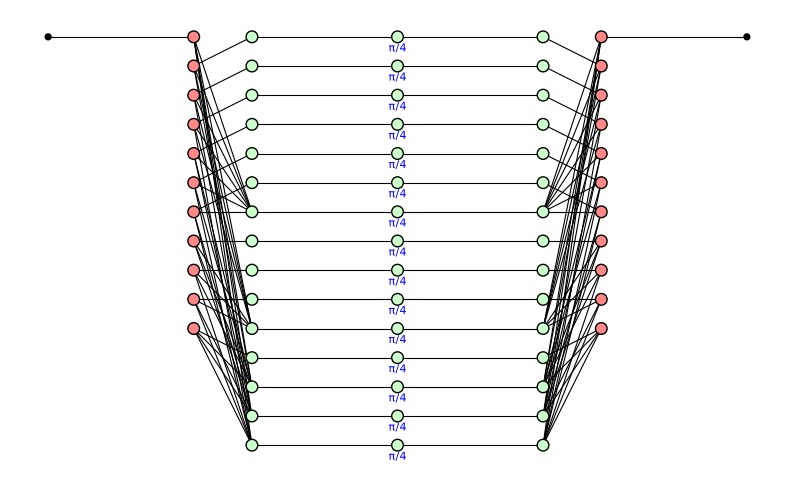

In [23]:
print(sum(1 for v in core15.composite.vertices() if core15.composite.type(v) != zx.VertexType.BOUNDARY), "spiders")
zx.draw_matplotlib(core15.composite, figsize=(10, 6))

**Step 6. Simplify, but leave the phases alone.** `reduce_gpf` with `gadgets=False` brings the diagram to its normal form without combining the non-Clifford phases. What is left: the input on a green spider (top left), four green spiders for the X-checks, the output (top right), and each $T$ gate is now a *phase gadget*: a red spider joined to the bits that its qubit carries, with a green leaf holding $\pi/4$. Fifteen gadgets, one per qubit.

36 spiders


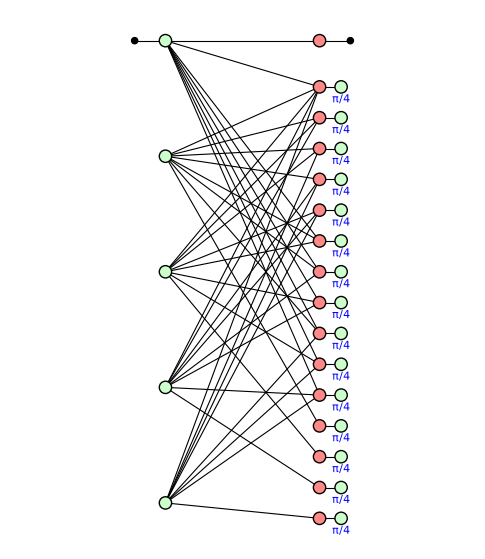

In [24]:
from zxqec.gpf import phase_polynomial, reduce_gpf

before = reduce_gpf(core15.composite, gadgets=False)
print(sum(1 for v in before.graph.vertices() if before.graph.type(v) != zx.VertexType.BOUNDARY), "spiders")
zx.draw_matplotlib(before.to_graph(), figsize=(6, 7))

**Step 7. Add the gadgets up: this is the check.** Every gadget multiplies the diagram by $e^{i \pi/4 \cdot (\text{parity of the bits it reads})}$. Writing each parity as a polynomial in the bits and adding over all fifteen gadgets gives one polynomial, the *phase polynomial* (`phase_polynomial`). Its coefficients count, for each bit, the gadgets that read it (mod 8), for each pair of bits the gadgets that read both (mod 4), and for each triple the gadgets that read all three (mod 2). That every term with an X-check bit vanishes is exactly the condition that the matrix of which gadget reads which bit is triorthogonal: the thesis's spider-nest identity. Here they all vanish, and fifteen gadgets add up to a single term, $7\pi/4$ times the logical bit:

In [25]:
poly, gadgets = phase_polynomial(before.graph)
(logical_bit,) = before.graph.neighbors(before.graph.inputs()[0])     # the input's green spider
print(len(gadgets), "gadgets add up to", len(poly), "term(s):")
for monomial, coefficient in poly.items():
    names = ['logical bit' if v == ('z', logical_bit) else 'an X-check bit' for v in monomial]
    print("   ", coefficient, "pi  x ", " * ".join(names))

15 gadgets add up to 1 term(s):
    7/4 pi  x  logical bit


A phase $7\pi/4$ on the logical bit is $T^\dagger$. Simplified with the gadget step, the whole composite is that: the input, the output, and one gadget with $7\pi/4$.

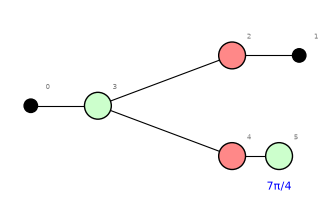

In [26]:
after = reduce_gpf(core15.composite)
zx.draw_matplotlib(after.to_graph(), labels=True, figsize=(4, 2.5))

**Step 8. The answer, and the checks.** The simplified diagram depends on no measurement result, so there is one class of runs, and its $2 \times 2$ matrix is $\mathrm{diag}(1, e^{-i\pi/4})$, which is $T^\dagger$ up to a phase. Separately, `stays_in_code` checks that the block maps the code into itself, so this is a logical gate and not a map that leaves the code. Every step above is an equality of maps (up to a scalar), so the four-spider diagram *is* $E^\dagger B E$. As a cross-check, building the composite from the ideal encoder instead, with the layer left in (`via='encoder'`), gives the same answer.

In [27]:
m = act15.matrix(act15.branches()[0].outcomes)
print("matrix (first entry scaled to 1):", np.round(m / m[0, 0], 3).tolist())
print("stays in the code:", act15.stays_in_code())
print("verdict:", act15.verdict())
print("through the ideal encoder instead:",
      logical_action(transversal_t.to_graph(), code15, code15, via='encoder').verdict())

matrix (first entry scaled to 1): [[(1+0j), (-0+0j)], [0j, (0.707-0.707j)]]


stays in the code: True
verdict: deterministic: every run implements T^dag


through the ideal encoder instead: deterministic: every run implements T^dag


## What is not covered

When a Clifford gate is applied only in *some* runs (here `S` on qubit 0 when a random bit `m` is 1), the code itself differs between runs. The tool cannot read such a code, and says so in the block's row instead of guessing:

In [28]:
p = QProgram(8, bits=1, initial_states={**{q: '0' for q in range(7) if q != 3}, 7: '+'})
c = Circuit(8, bit_amount=1)
for gate in steane_encoder(list(range(7))):
    c.add_gate(gate)
c.add_gate(Measurement(7, result_symbol='m'))
p.add_circuit(c, name='encode, and a random bit m')
c = Circuit(8, bit_amount=1)
c.add_gate(ParityControlled('S', 0, ['m']))
p.add_circuit(c, name='S if m = 1')
s = p.summary(0)
print(s.table())
print()
print([msg for ok, msg in s.blocks[1].checks if not ok][0])

block                         role  code before  code after  logical action  every run?  checks
0 encode, and a random bit m  -     [[1,1,1]]    [[7,1,3]]   I               yes         ok
1 S if m = 1                  -     [[7,1,3]]    ?           ?               ?           1 problem(s)

the code after the block could not be identified: a Clifford phase controlled by measurement outcomes gives the X stabilizer on qubits 0, 1, 2, 4 a Z part (or a factor i) in some runs only, so the code differs between runs; reading it run by run is not implemented


The same checks are in the test suite (`tests/test_noncss.py`), which also compares the ideal encoder of 27 codes that are not CSS with its definition, and the logical action of 49 stages of random programs with `B E_in = E_out L`.